# Signal Detection Analysis

## Questions
1) Why is the pert start argument in `compute_d_prime` a value of 106? Is it because there were 6 practice trials following 100 trial baseline block? 
2) Is 'SN' consistent across experimental sessions? Confirm.
3) Adding 0.5 to hits and false alarms. Correct method? Citation, description, etc.
4) Are you supposed to exclude "no perturbation" trials from d-prime calculation?
5) For d'=1, do you interpolate on individual level and then average estimates? Or do you interpolate once based on everyone's data?
6) In compute d' function, shouldn't we remove zero deg rotation trials from what is considered 'signal' trials? 

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import numpy.ma as ma
import pandas as pd
import scipy as sp
import seaborn as sns
from scipy import stats
from scipy.stats import bootstrap
from scipy.stats import norm
from scipy.stats import linregress

import statsmodels.api as sm
from statsmodels.formula.api import ols

# # Suppress warnings (temporary)
# warnings.simplefilter(action='ignore', category=FutureWarning)
# warnings.simplefilter(action='ignore', category=DeprecationWarning)

# Set some defaults
# custom_cmap = LinearSegmentedColormap.from_list("custom", ["#F1F744", "#D49BFF"])
sns.set_theme(context="paper", font_scale=1.2)
sns.set_style("ticks")
plt.rcParams["mathtext.default"] = "regular"
plt.rc("axes.spines", top=False, right=False)

%matplotlib inline
%config InlineBackend.figure_format = 'retina'

In [2]:
# df_sdt = pd.read_csv("data/sdt_FINAL.csv")
df_sdt = pd.read_csv("data/processed-sdt.csv")

# change perturbation detection column name to something shorter
df_sdt.rename(columns={'pert_resp': 'det'}, inplace=True)
df_sdt["rotation"] = df_sdt["delta_xv"]

df_sdt.reset_index(drop=True, inplace=True)
df_sdt.columns

Index(['si', 'SN', 'id', 'tester', 'TN', 'move_cycle', 'hX', 'hY', 'rot_hX',
       'rot_hY', 'delta_xv', 'tgt_jump', 'hand_max_dist', 'radvelmax', 'tgtX',
       'tgtY', 'rot_hand_theta', 'x_f', 'raw_ep_hand_ang', 'tgt_ang',
       'tgt_dist', 'vis_fb', 'MT', 'RT', 'ST', 'det', 'session', 'pert_trial',
       'x_f_z', 'x_f_outlier', 'no_fit', 'x_f_mean', 'x_f_clean',
       'sigma_motor_sdt', 'rotation'],
      dtype='str')

In [3]:
def compute_dp1_linear(df: pd.DataFrame, x_col: str, y_col: str, subj_col: str, s: int):
    
    subj = df[df[subj_col] == s]

    slope, intercept, _, _, _ = linregress(subj[x_col], subj[y_col])
    x_at_y1 = (1 - intercept) / slope

    return slope, intercept, x_at_y1


def compute_d_prime(df: pd.DataFrame, s: int, collapsed: bool, pert_start: int, subj_col: str, rot_col: str, det_col: str):
    
    """
    Compute d' values across rotation conditions for a given subject using signal detection theory.

    Parameters:
        df (pd.DataFrame): The full dataset.
        subj_col (str): Column name for subject IDs.
        rot_col (str): Column name for rotation/perturbation levels.
        s (int): Subject ID to filter on.
        det_col (str): Column name for binary detection responses (1 = detected, 0 = not).

    Returns:
        pd.DataFrame: DataFrame with columns ['SN', 'rotation', 'd prime'].
    """

    # NOTE: Add a 'collapsed' boolean for collapsing rotations. Will be necessary for linear fitting.

    # Select subject s and only select experimental trials
    subj = df[df[subj_col] == s].iloc[pert_start:].copy()

    # Collect rotations and responses
    if collapsed:
        subj[rot_col] = subj[rot_col].abs()

    perts = subj[rot_col].unique()
    # HK adding this next line to remove 0 deg rotations
    perts = perts[perts != 0]
    pert_responses = subj[det_col]

    # Calculate z score for FAs
    noise_trials = len(subj[subj[rot_col] == 0])
    false_alarms = len(subj[(pert_responses == 1) & (subj[rot_col] == 0)])
    false_alarm_rate = (false_alarms + 0.5) / (noise_trials + 1)
    z_false_alarm = norm.ppf(false_alarm_rate)

    # Init df for collecting d prime vals
    # df_sdt = pd.DataFrame(columns=['SN', 'rotation', "d prime"])
    df_sdt = pd.DataFrame()

    # Loops through perts and calculate d prime
    # Concat to df
    for p in perts:
        signal_trials = len(subj[subj[rot_col] == p])
        hits = len(subj[(pert_responses == 1) & (subj[rot_col] == p)])
        hit_rate = (hits + 0.5) / (signal_trials + 1)
        z_hit = norm.ppf(hit_rate)
        d_prime = z_hit - z_false_alarm

        new_row = pd.DataFrame({'SN': [int(s)], 'rotation': [float(p)], 'd prime': [d_prime]})
        df_sdt = pd.concat([df_sdt, new_row], ignore_index=True)
        df_sdt = df_sdt.sort_values(by="rotation").reset_index(drop=True)

    return df_sdt


def compute_dp1_log(df: pd.DataFrame, x_col: str, y_col: str, subj_col: str, s: int):
    
    subj = df[df[subj_col] == s]

    x = subj[x_col].values
    y = subj[y_col].values
    valid = x > 0
    x = x[valid]
    y = y[valid]

    def log_func(x, slope, intercept):
        return slope * np.log(x) + intercept

    params, _ = curve_fit(log_func, x, y)
    slope, intercept = params
    x_at_y1 = np.exp((1 - intercept) / slope)

    return slope, intercept, x_at_y1


def compute_dp1_linear(df: pd.DataFrame, x_col: str, y_col: str, subj_col: str, s: int):
    
    subj = df[df[subj_col] == s]

    slope, intercept, _, _, _ = linregress(subj[x_col], subj[y_col])
    x_at_y1 = (1 - intercept) / slope

    return slope, intercept, x_at_y1


In [4]:
# Count number of outliers per participant
num_outliers = df_sdt.groupby("SN")["x_f_outlier"].sum()
print(num_outliers)

print(f"Total percent of outlier trials: {num_outliers.sum() / (800 * 16)}")

# Print proportion of trials removed
pct_outliers = num_outliers / df_sdt["TN"].max()
print(pct_outliers)

# Print stats
print(pct_outliers.min(), pct_outliers.max(), pct_outliers.mean())

SN
1      2
2      2
3     23
4      2
5      4
6      3
7      4
8      4
9      6
10     3
11     6
12     1
13     1
14     5
15     0
16     5
Name: x_f_outlier, dtype: int64
Total percent of outlier trials: 0.005546875
SN
1     0.002208
2     0.002208
3     0.025386
4     0.002208
5     0.004415
6     0.003311
7     0.004415
8     0.004415
9     0.006623
10    0.003311
11    0.006623
12    0.001104
13    0.001104
14    0.005519
15    0.000000
16    0.005519
Name: x_f_outlier, dtype: float64
0.0 0.025386313465783666 0.004897902869757175


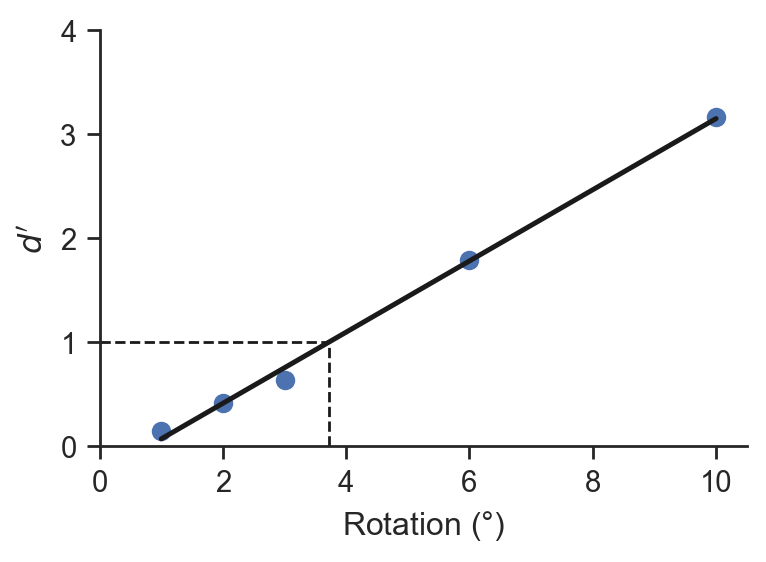

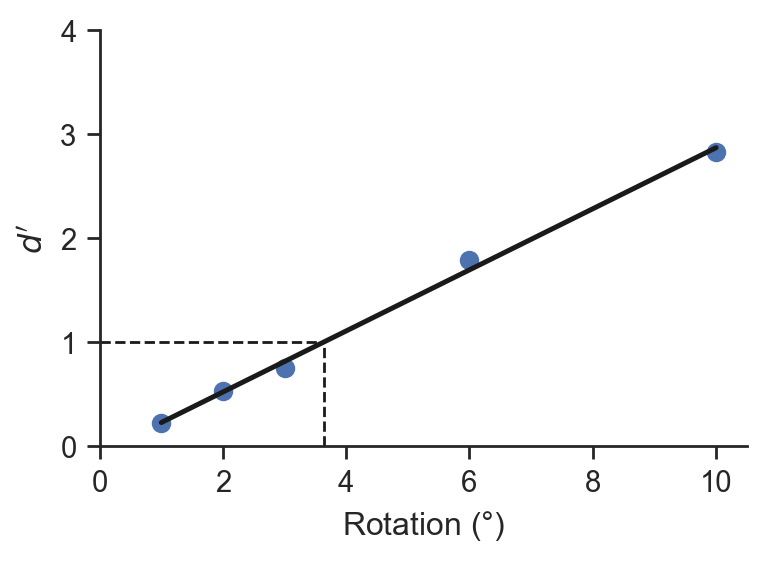

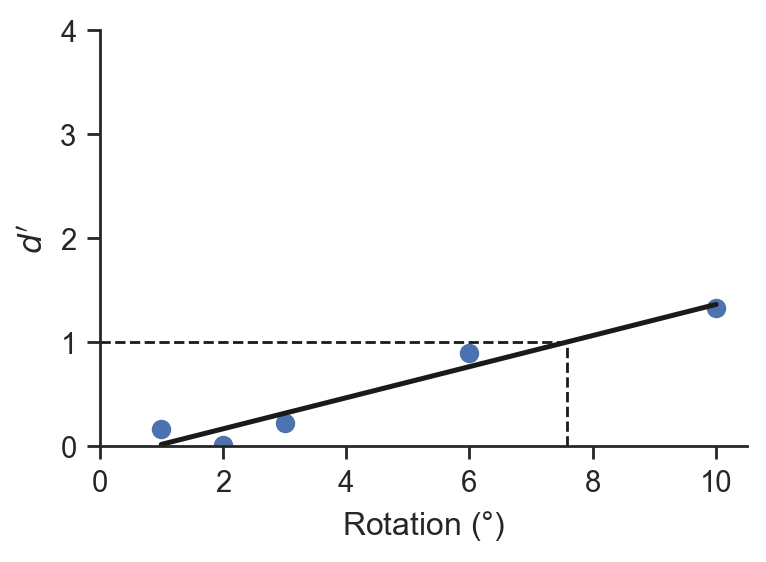

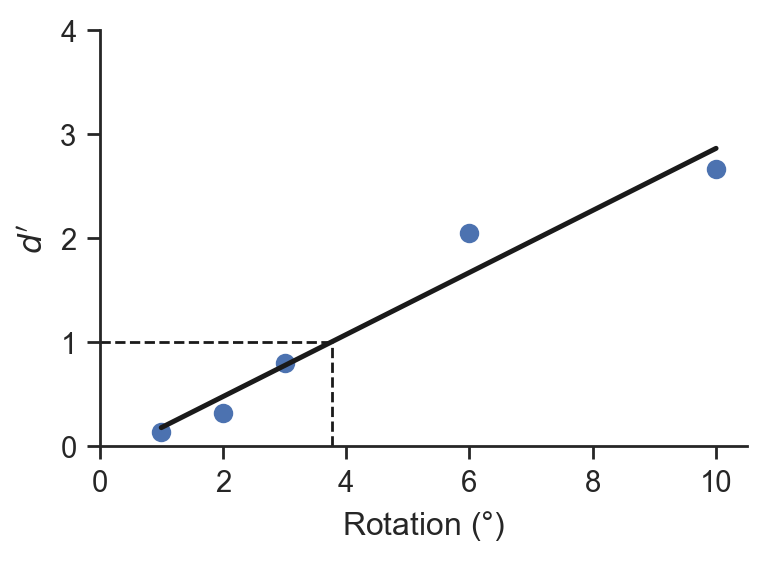

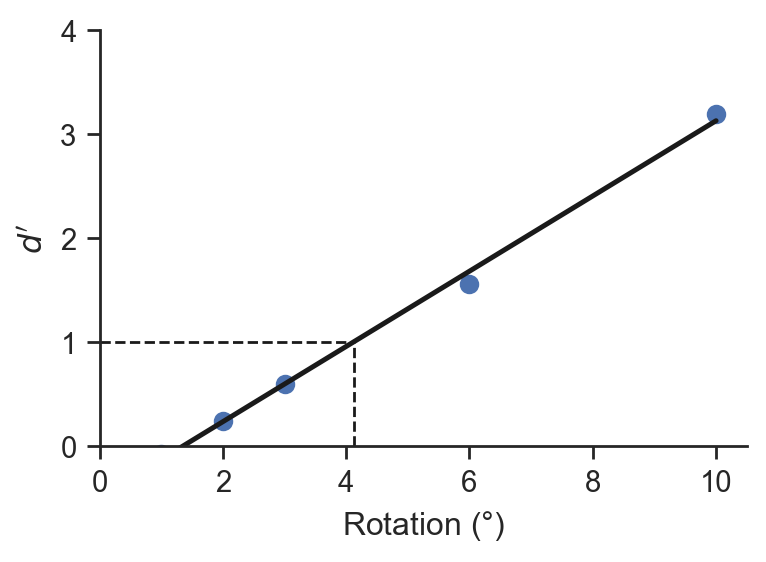

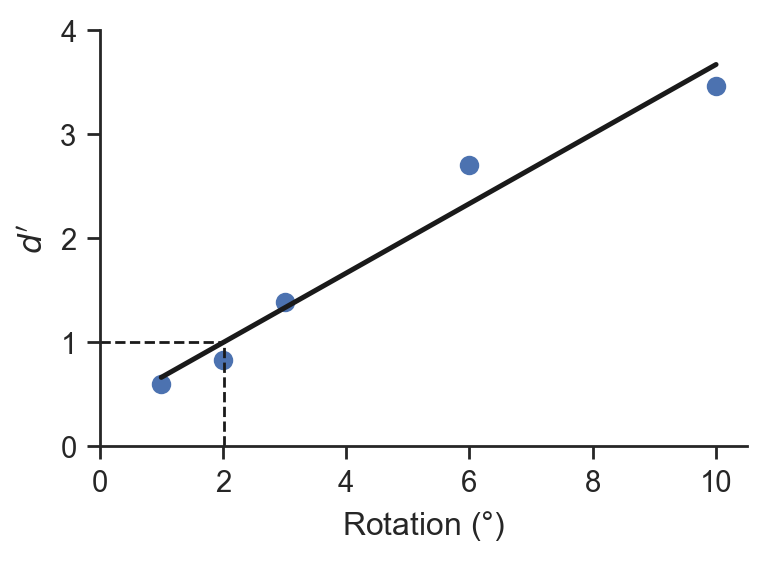

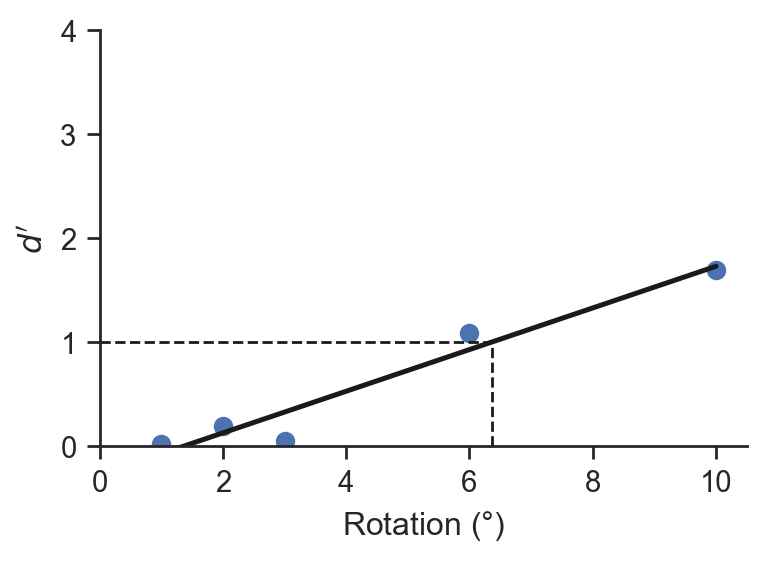

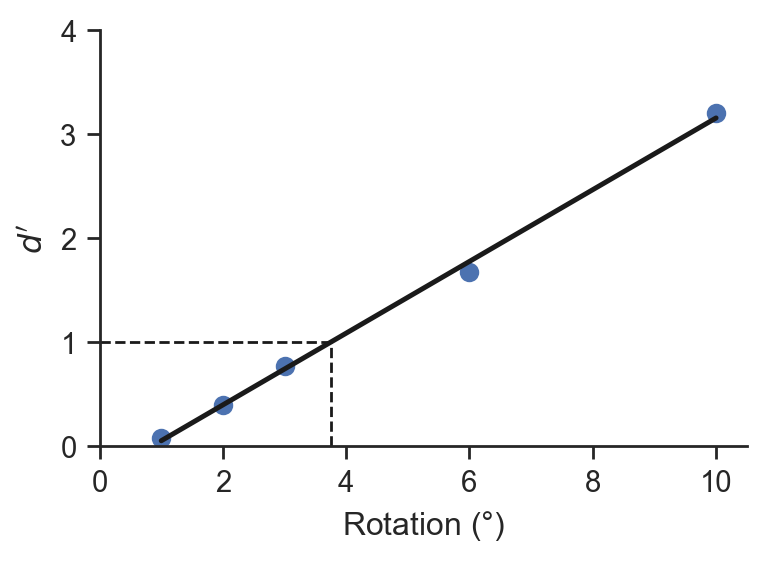

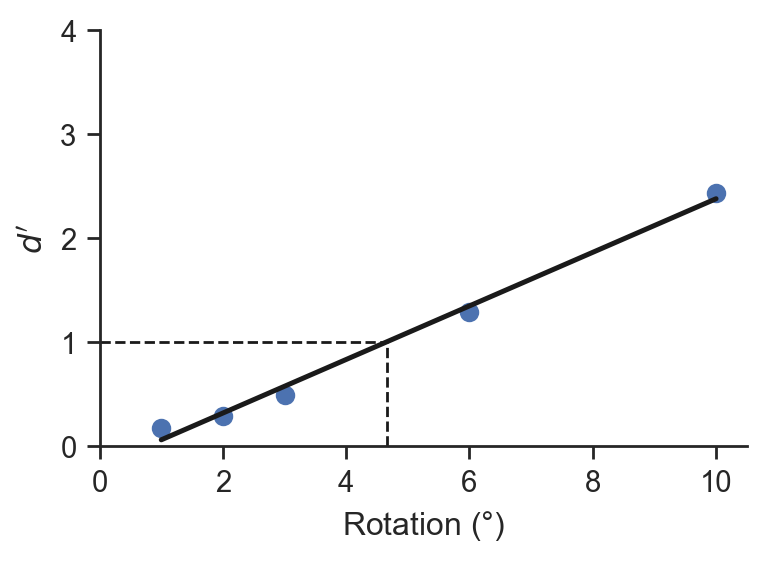

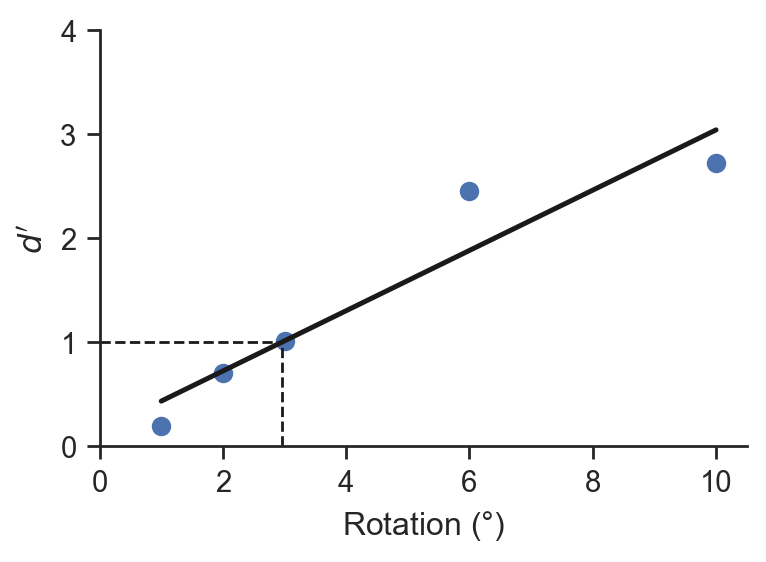

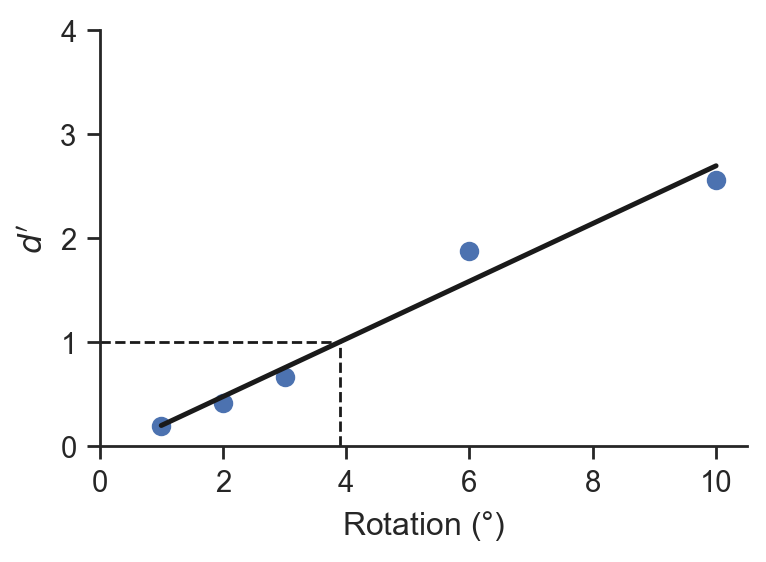

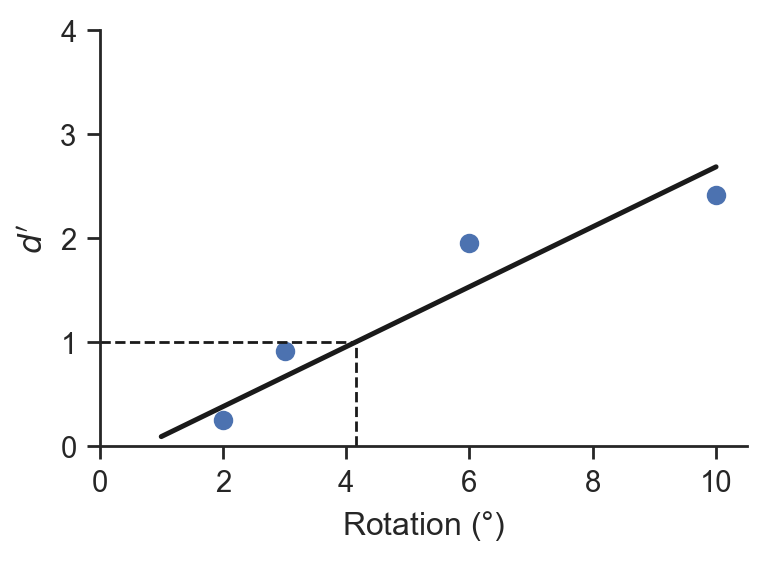

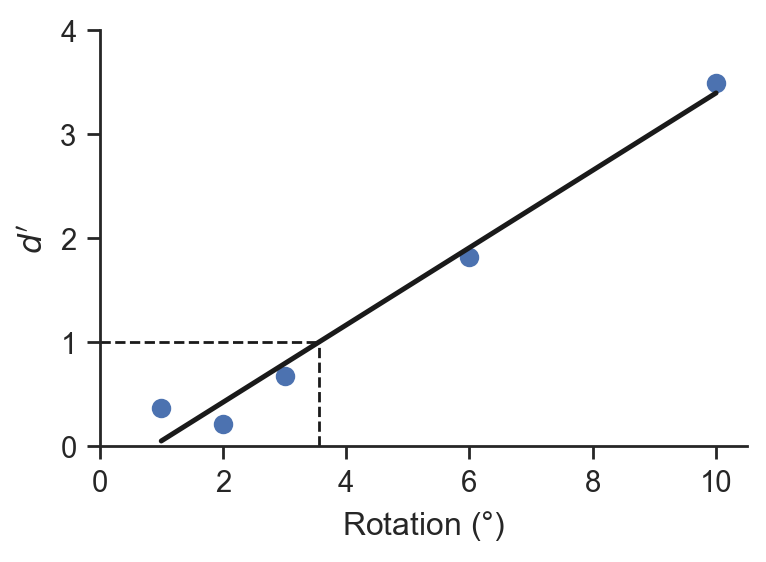

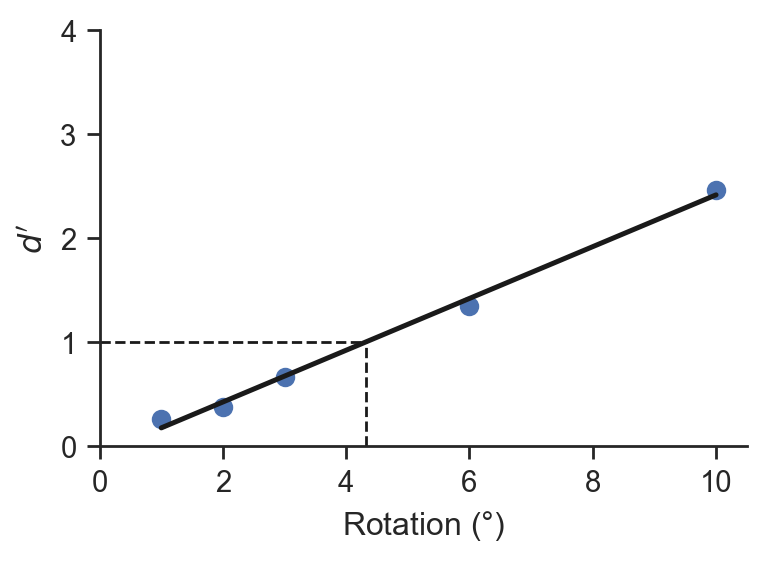

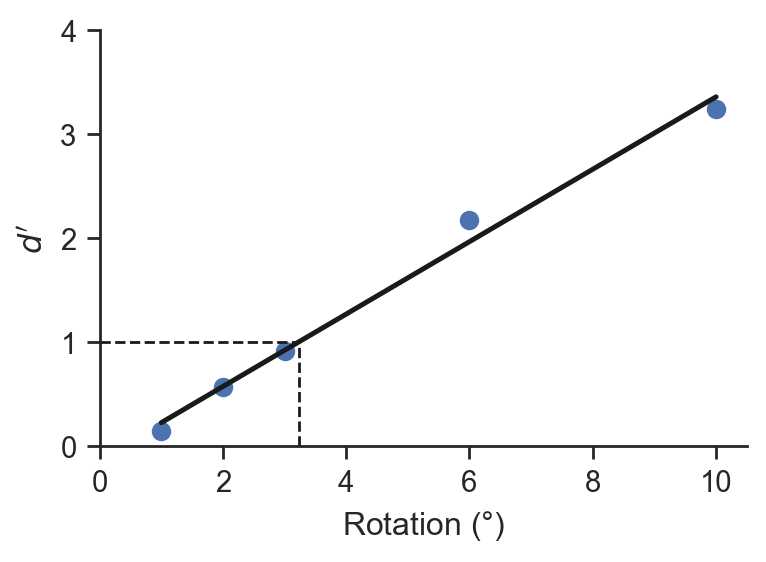

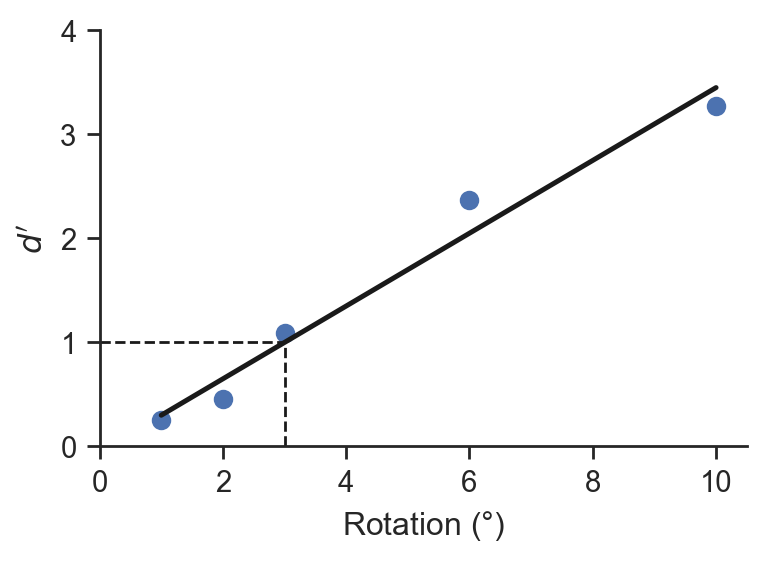

In [5]:
# Plot individual subject data - log vs linear fits
save_fig = True

# Initialize dataframe
dprimes = pd.DataFrame()
dprime_1_ege = np.zeros(len(df_sdt['SN'].unique()))
for k, s in enumerate(df_sdt['SN'].unique()):
    df_dp = compute_d_prime(df_sdt, s, True, 106, "SN", "rotation", "det")
    dprimes = pd.concat([dprimes, df_dp])

    # d' = 1 for linear fit
    slope, intercept, r, p_val, std_err = linregress(df_dp['rotation'], df_dp['d prime'])
    dprime_1_ege[k] = (1 - intercept) / slope
    
    fig, ax = plt.subplots(figsize=(4, 3))
    ax.plot(df_dp["rotation"], df_dp["d prime"], marker="o", markersize=6, linestyle=" ")
    sns.regplot(df_dp, x=df_dp["rotation"], y=df_dp["d prime"], color="k", ci=0, ax=ax)
    ax.set(xlim=[0, 10.5], ylim=[0, 4.0])
    ax.hlines(y=1, xmin=0, xmax=dprime_1_ege[k], color="k", linestyle="--", linewidth=1)
    ax.vlines(x=dprime_1_ege[k], ymin=0, ymax=1, color="k", linestyle="--", linewidth=1)
    ax.set(xlabel="Rotation ($\degree$)", ylabel=r"$\mathit{d'}$")
    
    fig.tight_layout()
    
    if (save_fig) & (k == 0):
        fig.savefig("../figs/pert-detect-subj.pdf")
        

In [6]:
dprimes.groupby("rotation")["d prime"].describe()

,count,mean,std,min,25%,50%,75%,max
rotation,,,,,,,,
1.0,16.0,0.165994,0.173942,-0.176672,0.117258,0.167965,0.225568,0.596035
2.0,16.0,0.385078,0.204719,0.006883,0.245718,0.383618,0.474133,0.828616
3.0,16.0,0.725172,0.318136,0.049161,0.623589,0.714409,0.909495,1.381640
6.0,16.0,1.800908,0.494461,0.897279,1.504868,1.806150,2.080918,2.706598
10.0,16.0,2.758925,0.614359,1.322720,2.455251,2.776490,3.215571,3.493086


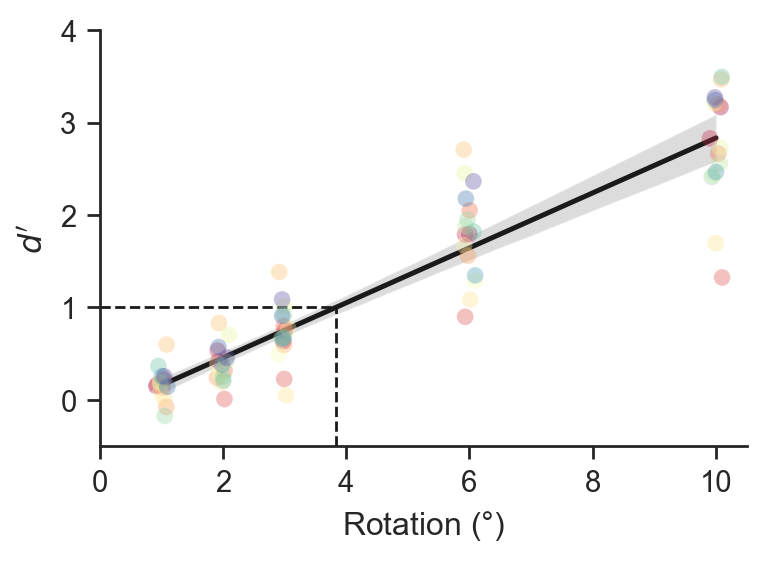

In [7]:
# Interpolate d'=1 for individuals and at group level
slope, intercept, r, p_val, std_err = linregress(dprimes['rotation'], dprimes['d prime'])
interp_dprime = (1 - intercept) / slope

# Plot
fig, ax = plt.subplots(figsize=(4, 3))
sns.regplot(dprimes, x="rotation", y="d prime", color="k", marker="", ax=ax)
sns.stripplot(
    dprimes, x="rotation", y="d prime", hue="SN", palette=sns.color_palette("Spectral", as_cmap=True), 
    alpha=0.35, s=6, native_scale=True, legend=False, ax=ax
)
ax.set(xlim=[0, 10.5], ylim=[-0.5, 4], yticks=np.arange(0, 4.1, 1), xlabel="Rotation ($\degree$)", ylabel=r"$\mathit{d'}$")
ax.vlines(x=interp_dprime, ymin=ax.get_ylim()[0], ymax=1, color="k", linestyle="--", linewidth=1)
ax.hlines(y=1, xmin=0, xmax=interp_dprime, color="k", linestyle="--", linewidth=1)
fig.tight_layout()
plt.show()

fig.savefig("../figs/pert-detect-group.pdf")


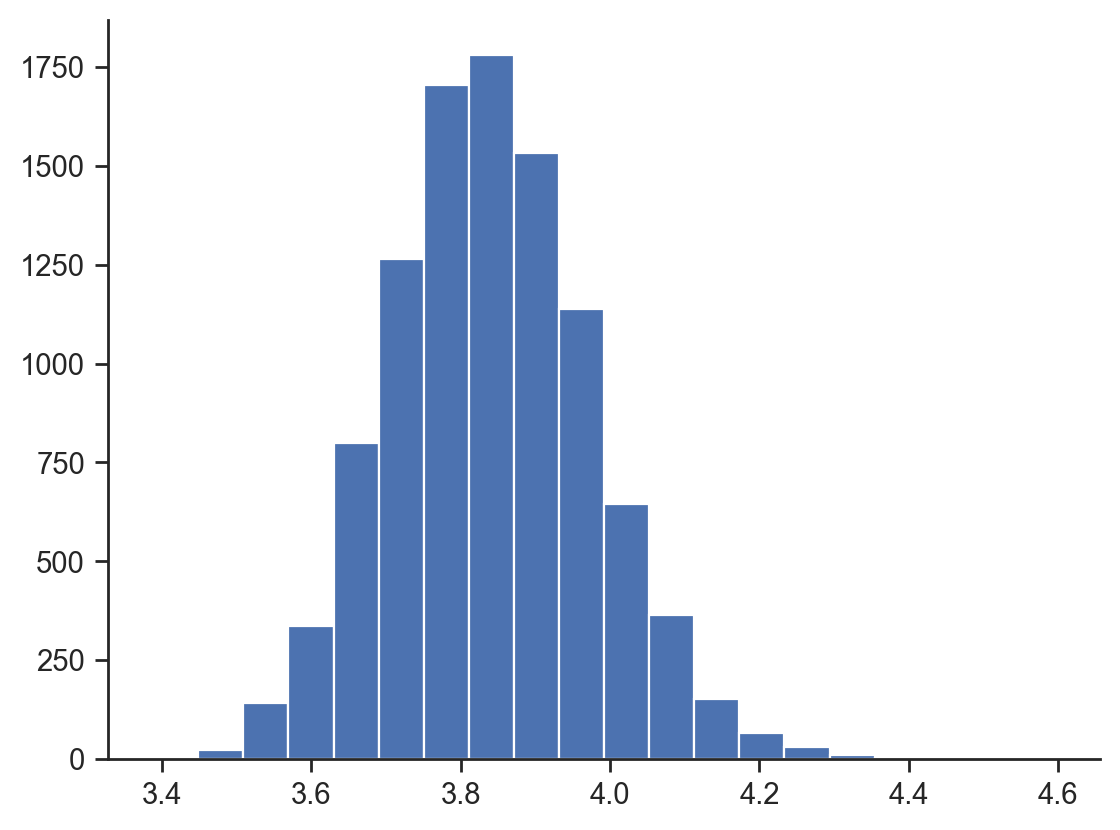

In [8]:
# Create bootstrapped distribution of d' 
dprimes_boot = pd.concat([
    dprimes.sample(frac=1, replace=True).assign(replicate=n)
    for n in range(10000)
])


# Group by replicate and apply linregress
res = dprimes_boot.groupby("replicate").apply(lambda x: linregress(x["rotation"], x["d prime"]))

# Compute interpolated d'=1 on bootstrapped samples (index 0: slope; index 1: intercept)
(1 - intercept) / slope
dprime_1_boot = res.apply(lambda x: (1 - x[1]) / x[0])

# Compute empirical 95% CI
ci_bounds = dprime_1_boot.quantile([0.025, 0.975])

# Plot for sanity check
fig, ax = plt.subplots()
ax.hist(dprime_1_boot, bins=20)
plt.show()


1.7751273348442513 0.016398430583587146 0.6364779970348319


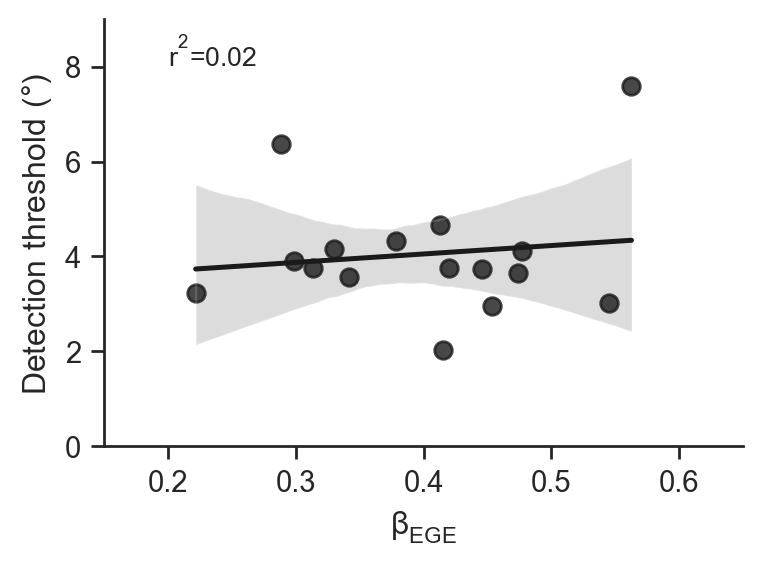

In [9]:
# Comparison of implicit vs explicit EGE sensitivity
df_compare = pd.read_csv("slopes.csv")
df_compare["dprime_interp"] = dprime_1_ege
df_compare["beta_ege_6ege_norm"] = (
    df_compare["beta_ege_6ege_bi"] 
    / (np.abs(df_compare["beta_ege_6ege_bi"]) + np.abs(df_compare["beta_ige_6ege_bi"]))
)

# Compute regression params
slope, intercept, r, p_val, std_err = linregress(df_compare["beta_ege_6ege_uni"], df_compare["dprime_interp"])
r2 = r**2
print(slope, r**2, p_val)

# Compare implicit adaptation sensitivity (-6:6 deg) to interpolated d'
fig, ax = plt.subplots(figsize=(4,3))
sns.regplot(data=df_compare, x="beta_ege_6ege_uni", y="dprime_interp", color="k", scatter_kws=dict(s=40), ax=ax)
ax.set(xlabel=r"$\beta_{EGE}$", ylabel=r"$Detection\ threshold\ (\degree)$", xlim=(0.15, 0.65), ylim=(0, 9))
# Add r2 value to plot
ax.text(0.2, 8, f"$r^2$={r2:.2f}", fontsize="small")
fig.tight_layout()
plt.show()
fig.savefig("../figs/beta-vs-dprime.pdf")




---
## Statistics

In [10]:
# Baseline motor variability
res = bootstrap((df_sdt["sigma_motor_sdt"].unique(),), np.mean, method="percentile")
print(f"Mean and 95% CI of baseline motor variability: {df_sdt.sigma_motor_sdt.mean()},{[res.confidence_interval]}")

# Interpolated d'=1 level from individual fits
res = bootstrap((dprime_1_ege,), np.mean, method="percentile")
print(f"Mean and 95% CI of interpolated d' of 1 pert levels: {dprime_1_ege.mean()},{[res.confidence_interval]}")

# Interpolated d'=1 from fitting all individuals at once
print(f"Mean and 95% CI of interpolated d' of 1 pert levels: {dprime_1_boot.mean()},{[ci_bounds.values]}")

Mean and 95% CI of baseline motor variability: 2.0678922705166944,[ConfidenceInterval(low=np.float64(1.8594602614947189), high=np.float64(2.2671394092236454))]
Mean and 95% CI of interpolated d' of 1 pert levels: 4.049297518061077,[ConfidenceInterval(low=np.float64(3.4845349437554707), high=np.float64(4.710155253314652))]
Mean and 95% CI of interpolated d' of 1 pert levels: 3.840046990122812,[array([3.59284586, 4.11535585])]
